## INF201 - Deliverable 1

### Group info:

ID: `G5_4`

Members:
* Stig Espen Paulsberg
* Vinicius Millan Santa Catharina
* Zaur Kambiev 

### Imports

In [2]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml
from tabulate import tabulate


### Client ID

Read the client ID from `config.yaml`

In [3]:
with open("config.yaml") as file:
    config = yaml.safe_load(file)

client_id = config["met_api"]["client_id"]

### Task 1

Request data from Meteorologisk Institutt 

(example source https://frost.met.no/python_example.html)

In [4]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id, ''))

# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print(f'Error! Returned status code {r.status_code}')
    print(f'Message: {json['error']['message']}')
    print(f'Reason: {json['error']['reason']}')

Data retrieved from frost.met.no!


Convert JSON into DataFrame

In [5]:
# This will return a Dataframe with all of the observations in a table format
table = pd.DataFrame()
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    table = pd.concat([table, row], ignore_index=True)

# These additional columns will be kept
columns = ['referenceTime', 'timeOffset', 'qualityCode', 'value', 'unit']
df = table[columns]

# Convert the time value to something Python understands
df['referenceTime'] = pd.to_datetime(df['referenceTime'])

df

,referenceTime,timeOffset,qualityCode,value,unit
0,2025-01-01 00:00:00+00:00,PT0H,0.0,-5.2,degC
1,2025-01-01 00:00:00+00:00,PT6H,NaN,-2.8,degC
2,2025-01-02 00:00:00+00:00,PT0H,0.0,-11.5,degC
3,2025-01-02 00:00:00+00:00,PT6H,NaN,-7.2,degC
4,2025-01-03 00:00:00+00:00,PT0H,0.0,-8.9,degC
...,...,...,...,...,...
723,2025-12-28 00:00:00+00:00,PT6H,NaN,-0.7,degC
724,2025-12-29 00:00:00+00:00,PT0H,0.0,-3.6,degC
725,2025-12-29 00:00:00+00:00,PT6H,NaN,-5.7,degC
726,2025-12-30 00:00:00+00:00,PT0H,0.0,-3.0,degC


Check for missing values

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 728 entries, 0 to 727
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   referenceTime  728 non-null    datetime64[us, UTC]
 1   timeOffset     728 non-null    str                
 2   qualityCode    364 non-null    float64            
 3   value          728 non-null    float64            
 4   unit           728 non-null    str                
dtypes: datetime64[us, UTC](1), float64(2), str(2)
memory usage: 28.6 KB


Observations:
* We have two entries per day: `timeOffset = PT0H` and `timeOffset = PT6H`. 

* For `timeOffset = PT6H`, the `qualityCode` field is not filled. 

Decision: 
* We will use only entries with `timeOffset = PT0H`, as they have `qualityCode` of `0`, indicating the highest data quality.

In [7]:
df = df[df["timeOffset"] == "PT0H"]

Make a plot

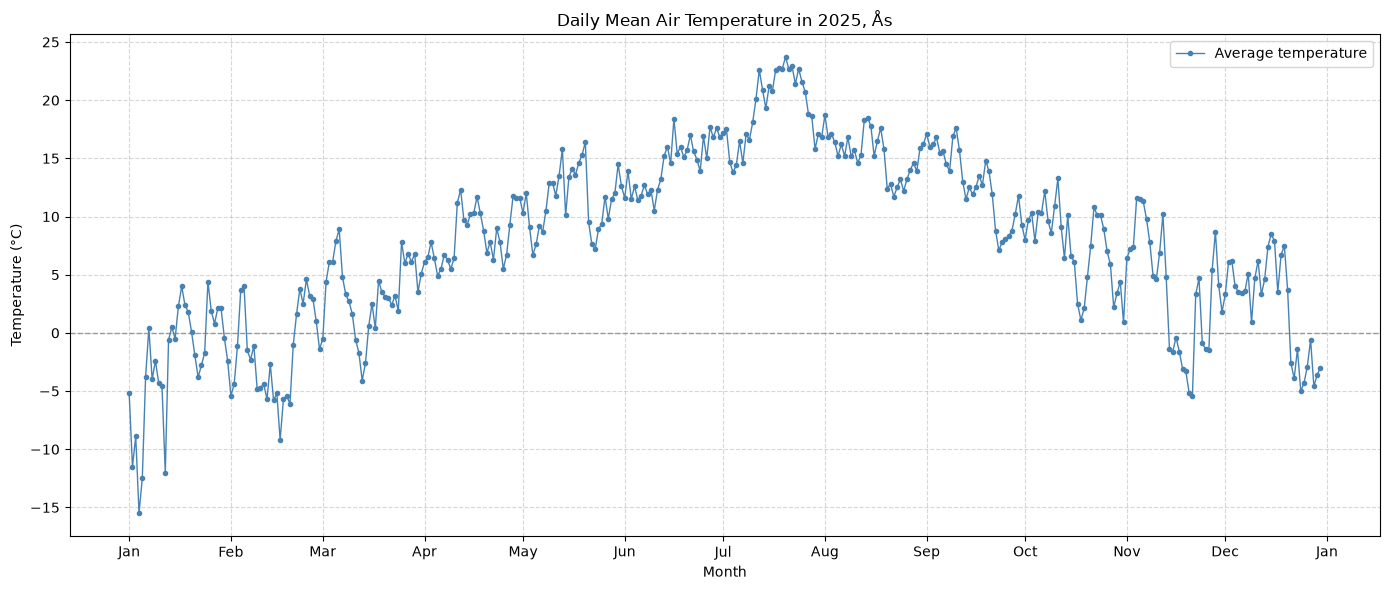

In [34]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["referenceTime"],
    df["value"],
    marker='o',
    linestyle='-',
    linewidth=1,
    markersize=3,
    color='steelblue',
    label='Average temperature'
)

# Zero-degree reference
plt.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.75
)

# Format dates
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))

# Labels
plt.title('Daily Mean Air Temperature in 2025, Ås')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')

# Styling
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()

Print a summary table

In [65]:
summary = (
    df["value"]
    .agg(["mean", "median", "min", "max"])
    .reset_index()
)
summary_table = (
    "Summary of Daily Mean Air Temperature in Ås (2025)\n"
    + tabulate(
        summary,
        headers=["Statistic", "Temperature (°C)"],
        tablefmt="outline",
        showindex=False,
        floatfmt=".2f"
    )
)
print(summary_table)

Summary of Daily Mean Air Temperature in Ås (2025)
+-------------+--------------------+
| Statistic   |   Temperature (°C) |
+=============+====================+
| mean        |               7.90 |
| median      |               8.40 |
| min         |             -15.50 |
| max         |              23.70 |
+-------------+--------------------+


### Task 2

Request precipitation data

In [66]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
 'sources': 'SN17850',
 'elements': 'sum(precipitation_amount P1D)',
 'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id, ''))
# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data_precip = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])


Data retrieved from frost.met.no!


In [ ]:
# This will return a Dataframe with all of the observations in a table format
# Intructions: https://frost.met.no/python_example.html

rows_precip = []

for i in range(len(data_precip)):
    row = pd.DataFrame(data_precip[i]['observations'])
    row['referenceTime'] = data_precip[i]['referenceTime']
    row['sourceId'] = data_precip[i]['sourceId']
    rows_precip.append(row)

df_precip = pd.concat(rows_precip, ignore_index=True)

df_precip['referenceTime'] = pd.to_datetime(df_precip['referenceTime'])

df_precip.head()

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId
0,sum(precipitation_amount P1D),5.4,mm,PT18H,P1D,0,C,2,NaN,2025-01-01 00:00:00+00:00,SN17850:0
1,sum(precipitation_amount P1D),6.6,mm,PT6H,P1D,0,C,2,0.0,2025-01-01 00:00:00+00:00,SN17850:0
2,sum(precipitation_amount P1D),0.0,mm,PT18H,P1D,0,C,2,NaN,2025-01-02 00:00:00+00:00,SN17850:0
3,sum(precipitation_amount P1D),1.9,mm,PT6H,P1D,0,C,2,0.0,2025-01-02 00:00:00+00:00,SN17850:0
4,sum(precipitation_amount P1D),0.1,mm,PT18H,P1D,0,C,2,NaN,2025-01-03 00:00:00+00:00,SN17850:0


In [ ]:
# Create a df with the precipiation measuremente of the PT6H timeOffset

df_precip_6H = df_precip[df_precip['timeOffset'] == "PT6H"]
df_precip_6H.head()

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId
1,sum(precipitation_amount P1D),6.6,mm,PT6H,P1D,0,C,2,0.0,2025-01-01 00:00:00+00:00,SN17850:0
3,sum(precipitation_amount P1D),1.9,mm,PT6H,P1D,0,C,2,0.0,2025-01-02 00:00:00+00:00,SN17850:0
5,sum(precipitation_amount P1D),0.1,mm,PT6H,P1D,0,C,2,0.0,2025-01-03 00:00:00+00:00,SN17850:0
7,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,2025-01-04 00:00:00+00:00,SN17850:0
9,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,2025-01-05 00:00:00+00:00,SN17850:0


In [ ]:
# Create a list with the total precipitation of each month for the PT6H timeOffset
monthly_total = []

for i in range(1,13):
    total = df_precip_6H[df_precip_6H['referenceTime'].dt.month==i]['value'].sum()
    monthly_total.append(total)

monthly_total

[np.float64(86.4),
 np.float64(38.800000000000004),
 np.float64(15.7),
 np.float64(21.6),
 np.float64(35.400000000000006),
 np.float64(93.3),
 np.float64(77.00000000000001),
 np.float64(110.30000000000001),
 np.float64(145.6),
 np.float64(124.89999999999999),
 np.float64(84.89999999999998),
 np.float64(116.3)]

In [ ]:
# one date for each month (15)
months_dates = []

for i in range(1,13):
    date = "2025-"+str(i)+"-15"
    months_dates.append(date)

months_dates = pd.to_datetime(months_dates)


DatetimeIndex(['2025-01-15', '2025-02-15', '2025-03-15', '2025-04-15',
               '2025-05-15', '2025-06-15', '2025-07-15', '2025-08-15',
               '2025-09-15', '2025-10-15', '2025-11-15', '2025-12-15'],
              dtype='datetime64[us]', freq=None)


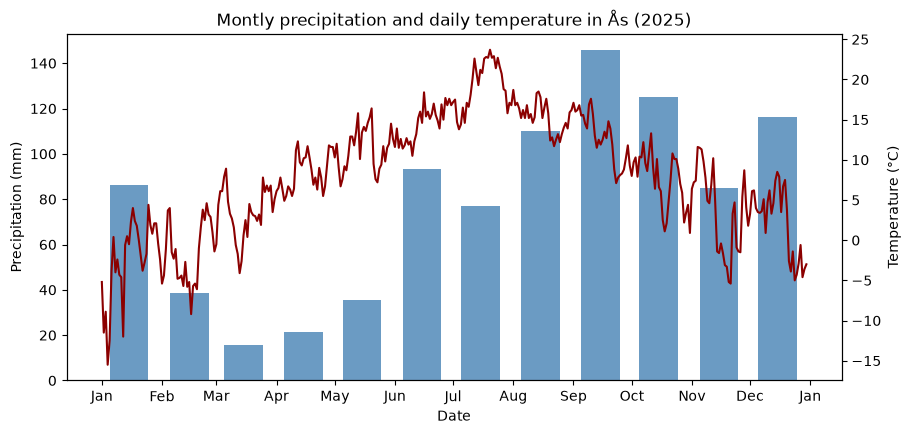

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax2 = ax1.twinx()

ax1.bar(
    months_dates,        
    monthly_total,
    width=20,
    alpha=0.8,
    color='steelblue'
)
ax1.set_ylabel("Precipitation (mm)")
ax1.set_xlabel("Date")
ax1.set_title("Montly precipitation and daily temperature in Ås (2025)")
ax2.plot(
    df_temp['referenceTime'],
    df_temp['value'],
    color='darkred'
)
ax2.xaxis.set_major_locator(mdates.MonthLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax2.set_ylabel("Temperature (°C)")

plt.show()

### Task 3

### Task 4

### Task 5

Define a function for moving average 

In [26]:
def rolling_mean(
        values: pd.Series,
        window: int = 7
) -> pd.Series:
    """
    Returns rolling average for the input Series.

    Args:
    values: pd.Series with numerical values.
    window: Size of rolling window. Default value is 7.

    Returns:
    pd.Series with average values in window.
    """

    return (
        values
        .rolling(
            window=window,
            center=True,
            min_periods=1
        ).mean()
    )

Apply to the 2025 mean temperature

In [27]:
df["rolling_mean"] = rolling_mean(df["value"])

Make a plot

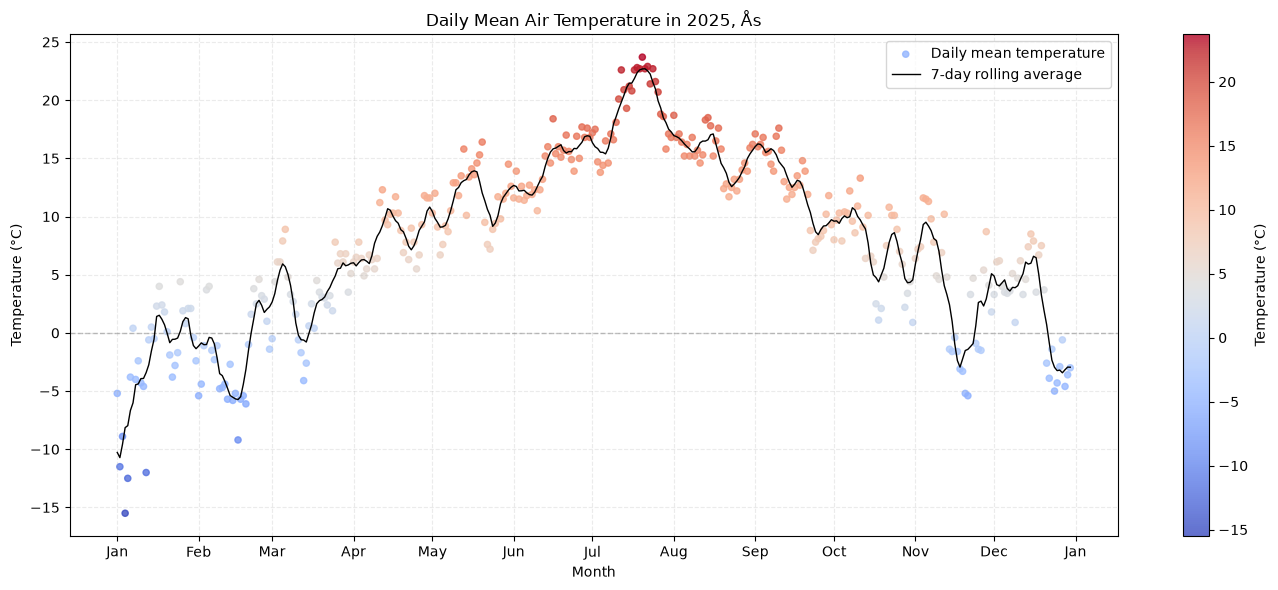

In [29]:
plt.figure(figsize=(14, 6))

# Color-coded daily temperatures
scatter = plt.scatter(
    x=df["referenceTime"],
    y=df["value"],
    c=df["value"],
    cmap="coolwarm",
    s=20,
    alpha=0.8,
    label="Daily mean temperature"
)

# Smoothed temperature curve
plt.plot(
    df["referenceTime"],
    df["rolling_mean"],
    color="black",
    linewidth=1,
    label="7-day rolling average",
    zorder=3
)

# Colorbar
plt.colorbar(scatter, label="Temperature (°C)")

# Zero-degree reference
plt.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.5
)

# Format dates
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))

# Labels
plt.title('Daily Mean Air Temperature in 2025, Ås')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')

# Styling
plt.grid(True, linestyle='--', alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()